# Build and benchmark a Steane-swap QEC cycle

Syndrome extraction with bare ancillas can spread a single fault to several data qubits; for the Steane code, this reduces the fault distance of a memory circuit from 3 to 2, as shown in the [fault-tolerance certificates notebook](5_fault_tolerance_certificates.ipynb).
Steane-type quantum error correction (QEC) avoids this problem by coupling the data block to a freshly prepared encoded block through a transversal CNOT, which does not spread errors within a block.
Measuring one of the two blocks then reveals syndrome information.
The fresh blocks must themselves be free of high-weight errors, so we prepare them with the flagged circuit from the [state-preparation notebook](4_state_preparation.ipynb) and discard attempts in which a flag fires.

In the Steane-swap variant, shown in Figure 4d of [arXiv:2603.04584](https://arxiv.org/abs/2603.04584), the transversal CNOT teleports the logical state onto the fresh block, and the old block is measured out.
One QEC cycle consists of an X-correction step followed by a Z-correction step, which together return the logical state to its starting block with at most two code blocks in use at any time.
This sequence is equivalent to Knill QEC, a teleportation-based correction scheme, with its two transversal CNOTs applied in sequence rather than in parallel.

Below, we build one Steane-swap QEC cycle for the seven-qubit Steane code and estimate its logical error rate and discard rate under depolarizing noise.

## Setup

Run the next cell once in a fresh notebook environment.
IPython's `%pip` magic installs into the active kernel, so the following imports use the same environment.

In [1]:
%%capture
%pip install qldpc matplotlib

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import sinter
import stim

from qldpc import circuits, codes, decoders
from qldpc.objects import Pauli

NUM_WORKERS = 1

## Fresh code blocks

For a fresh logical-zero block, we use the flagged preparation circuit from the [state-preparation notebook](4_state_preparation.ipynb), which follows Figure 1c of [Goto (2016)](https://www.nature.com/articles/srep19578).
The flag qubit catches single faults that would otherwise leave a high-weight error on the prepared block.
A repeat-until-success protocol would prepare the block again whenever its flag fires, before allowing it to interact with the data.
Our simulation conditions on those flag checks passing; it does not simulate retries or their timing.
Applying transversal Hadamards to the seven data qubits of the logical-zero preparation gives the matching logical-plus preparation, while the eighth (flag) qubit is not transformed.
The preparation begins with a reset so that a block can be reused after it is measured out.

In [3]:
code = codes.SteaneCode()

# |0> state prep circuit
zero_prep_circuit = stim.Circuit("""
    R 0 1 2 3 4 5 6 7
    # non-fault-tolerant state preparation
    H 0 2 4
    CX 0 3 2 1 4 5
    CX 0 1 2 6 4 3
    CX 2 5 3 6
    # flag errors in a logical Z representative
    H 7
    CZ 7 1 7 3 7 5
    MX 7
    DETECTOR rec[-1]  # repeat-until-success flag
""")

# |+> state prep circuit
plus_prep_circuit = zero_prep_circuit.copy()
plus_prep_circuit.append("H", range(len(code)))

## One Steane-swap step

An X-correction step prepares a fresh block in $|+_L\rangle$, applies a transversal CNOT from the fresh block onto the data block, and measures the data block in the Z basis.
Physical X errors on the data block do not propagate to the fresh block.
They instead flip Z-basis measurement outcomes, so every Z-type stabilizer of the measured block defines a detector.
The measured logical Z operator determines a logical X correction on the fresh block, which is tracked in software by including the logical measurement outcome in the Z-type logical observable.

A Z-correction step exchanges the roles of X and Z: the fresh block is prepared in $|0_L\rangle$ and is the target of the transversal CNOT, and the data block is measured in the X basis.

The helper below takes the measurement basis as its `basis` argument, so `basis=Pauli.Z` implements an X-correction step.

In [4]:
def get_steane_swap_step(
    basis: Pauli, old_block: circuits.QubitIDs, new_block: circuits.QubitIDs
) -> tuple[stim.Circuit, circuits.DetectorRecord]:
    """Teleport the logical state of old_block onto new_block by measuring old_block in a basis.

    A Z-basis measurement of old_block detects X errors; an X-basis measurement detects Z errors.

    Returns:
        stim.Circuit: The circuit for one Steane-swap step.
        circuits.DetectorRecord: A record of the flag and stabilizer detectors in the circuit.
    """
    # prepare a fresh code block, and identify the control and target of a transversal CNOT
    if basis is Pauli.Z:
        prep_circuit, control, target = plus_prep_circuit, new_block, old_block
    else:
        prep_circuit, control, target = zero_prep_circuit, old_block, new_block
    circuit = circuits.with_remapped_qubits(prep_circuit, new_block.data + new_block.ancilla)
    det_record = circuits.DetectorRecord({"flags": range(circuit.num_detectors)})

    # teleport the logical state onto the fresh block, measuring out the old block
    circuit.append("CX", [qubit for pair in zip(control.data, target.data) for qubit in pair])
    circuit.append(f"M{basis}", old_block.data)

    # detectors for the basis-type stabilizers, defined on the last len(code) measurements
    stabilizer_ops = code.get_stabilizer_ops(basis)
    for op_vec in stabilizer_ops:
        targets = [stim.target_rec(qubit - len(code)) for qubit in np.flatnonzero(op_vec)]
        circuit.append("DETECTOR", targets)
    det_record.append({basis: range(len(stabilizer_ops))})

    # Logical measurement outcomes determine a Pauli-frame correction to the fresh block, so they
    # are included in the basis-type logical observables.  X-type observables are numbered from 0
    # to code.dimension-1, while Z-type observables are numbered from code.dimension to
    # 2*code.dimension-1.
    circuit += circuits.get_observables(
        code,
        basis=basis,
        on_measurements=True,
        observable_indices=range(code.dimension * int(basis), code.dimension * (int(basis) + 1)),
    )
    return circuit, det_record

## Assemble a QEC cycle

We label two sets of seven data qubits as block 0 and block 1, each with a separate preparation-flag ancilla.
An input logical qubit starts on block 0, where it is noiselessly entangled with an ideal reference qubit.
As in the [combined-basis memory notebook](3_quantum_memory_combined.ipynb), this reference qubit is a simulation device that lets one circuit track both X-type and Z-type logical errors.
The X-correction step teleports the logical state from block 0 onto block 1, and the Z-correction step teleports it back onto the reset qubits of block 0.

Finally, every stabilizer of block 0 is measured without adding readout noise.
A -1 result then reveals a residual error on that block at the end of the QEC cycle.
The logical operators of block 0 complete the comparison between the output state and the input state.

| Correction step | Fresh block | Transversal CNOT | Measured block and basis | Output block | Logical measurement updates |
| --- | --- | --- | --- | --- | --- |
| X correction | Block 1 in $\lvert+_L\rangle$ | 1 → 0 | Block 0, Z | 1 | Z-type observable's Pauli frame |
| Z correction | Reset block 0 in $\lvert0_L\rangle$ | 1 → 0 | Block 1, X | 0 | X-type observable's Pauli frame |

In [5]:
# Each code block has len(code) data qubits and one flag qubit.  Block 0 additionally has one
# ideal reference qubit for each logical qubit of the code.
qubit_ids_0 = circuits.QubitIDs(len(code), ancilla=1, reference=code.dimension)
qubit_ids_1 = circuits.QubitIDs(len(code), ancilla=1).shift(qubit_ids_0.max() + 1)

# noiselessly entangle block 0 with its reference qubits, and annotate its logical observables
circuit = circuits.get_logical_bell_prep(code, qubit_ids_0.data, qubit_ids_0.reference)
circuit += circuits.get_observables(code, qubit_ids_0.data)
det_record = circuits.DetectorRecord()

# apply an X-correction step, followed by a Z-correction step
for basis, old_block, new_block in [
    (Pauli.Z, qubit_ids_0, qubit_ids_1),
    (Pauli.X, qubit_ids_1, qubit_ids_0),
]:
    step_circuit, step_det_record = get_steane_swap_step(basis, old_block, new_block)
    circuit += step_circuit
    det_record += step_det_record

# append final (noiseless) stabilizer and observable readout
stabilizer_ops = code.get_stabilizer_ops()
circuit += circuits.as_noiseless_circuit(
    circuits.get_pauli_product_measurements(stabilizer_ops, qubit_ids_0.data)
)
for meas_index in range(-len(stabilizer_ops), 0):
    circuit.append("DETECTOR", [stim.target_rec(meas_index)])
det_record.append({"final": range(len(stabilizer_ops))})
circuit += circuits.get_observables(code, qubit_ids_0.data)

## Add noise and decode

Active gates, resets, and measurements outside the noiseless input preparation and final readout receive depolarizing noise.
Detectors mark unexpected stabilizer and flag measurement parities, and we discard shots in which a flag detector fires.
A lookup-table decoder predicts logical-observable flips from the remaining shots' detector events, considering every combination of up to two error mechanisms in the circuit's detector error model (DEM), Stim's representation of which detectors and observables each circuit error can flip.
We use Sinter, Stim's sampling and decoding tool, to estimate the performance of this decoder on the noisy circuit.

The left panel shows the logical error rate after one QEC cycle, and the right panel shows the discard rate: the fraction of shots in which either preparation flag fires.
Shaded bands show rates whose binomial likelihood, given the observed counts, is within a factor of 1000 of the maximum.
The dotted line marks equality between the physical error rate and the logical error rate.

In [6]:
error_rates = np.logspace(-4, -2, 5)
sinter_decoder = decoders.SinterDecoder(decoder=decoders.lookup(max_weight=2))

# post-select on flags to model repeat-until-success preparation of fresh blocks
postselection_mask = np.zeros(circuit.num_detectors, dtype=np.uint8)
postselection_mask[det_record.get_events("flags")] = 1

# build sinter tasks to perform our simulations
tasks = [
    sinter.Task(
        circuit=circuits.DepolarizingNoiseModel(error_rate).noisy_circuit(circuit),
        postselection_mask=np.packbits(postselection_mask, bitorder="little"),
        json_metadata={"p": error_rate, "cycles": 1, "noise": "depolarizing_active_only"},
    )
    for error_rate in error_rates
]

# run simulations and collect statistics on error rates
stats = sinter.collect(
    tasks=tasks,
    decoders=["custom"],
    custom_decoders={"custom": sinter_decoder},
    num_workers=NUM_WORKERS,
    max_shots=1_000_000,
    max_errors=100,
)

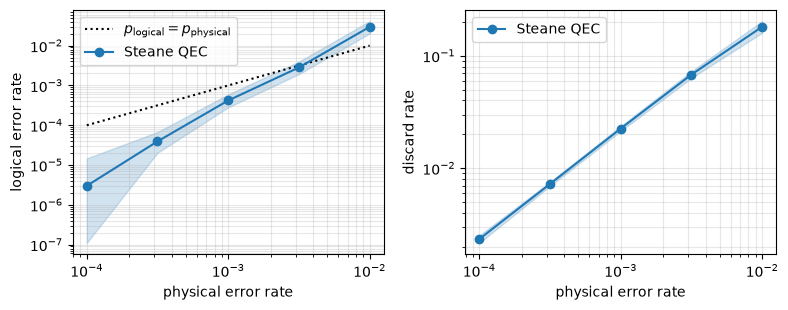

In [7]:
figure, (error_axis, discard_axis) = plt.subplots(1, 2, figsize=(8, 3.2))
error_axis.plot(
    error_rates,
    error_rates,
    color="black",
    linestyle=":",
    label=r"$p_{\mathrm{logical}}=p_{\mathrm{physical}}$",
)
for axis, plotter, label in (
    (error_axis, sinter.plot_error_rate, "logical error rate"),
    (discard_axis, sinter.plot_discard_rate, "discard rate"),
):
    plotter(
        ax=axis,
        stats=stats,
        x_func=lambda stat: stat.json_metadata["p"],
        plot_args_func=lambda _index, _curve_id: {"marker": "o", "label": "Steane QEC"},
    )
    axis.set_xlabel("physical error rate")
    axis.set_ylabel(label)
    axis.loglog()
    axis.grid(which="both", alpha=0.3)
    axis.legend(loc="best")
figure.tight_layout()
plt.show()

The logical error rate grows roughly quadratically with the physical error rate, as expected when every single fault in an accepted shot is corrected.
It falls below the physical error rate when the physical error rate is below roughly $3\times10^{-3}$.
The discard rate grows linearly, because a single fault can fire a flag.

You can explore other preparations or block layouts by changing them together with their detector and observable annotations.